# MSH chain: dense Python reference for `msh_chain_ldos.ipynb`

Adapted from `ferromagnetic_spin_chain_edit_ver2.ipynb`. This notebook reruns the calculations of the
TensorBinding notebook `msh_chain_ldos.ipynb` with the dense NumPy BdG code from the earlier work, so
the two can be compared number by number. Every printed table has the same layout as the matching
Julia cell, and all arrays are saved to `msh_compare_python.npz` at the end.

| Section here | Julia notebook | Quantity |
|---|---|---|
| 1 | `msh_chain`, `reference` checks | spectrum, particle–hole symmetry |
| 2 | f sweep | $\|E\|_1$, $\|E\|_3$ vs rotation fraction $f$ |
| 3 | Lorentzian LDOS ($\eta = 0.03$) | particle and hole LDOS, 4 snapshots of the spin ramp |
| 4 | `kpm_exact` / `get_ldos_spatial` | Jackson-KPM LDOS of the ramp snapshots, sum rule (section 8a) |
| 5 | `majorana_fermion` | Majorana centers, $C\gamma = \gamma$, $E_f$ |
| 6 | `majorana_pair_charge` | $\Delta Q$ vs segment length $\ell$, $\delta n(x)$ |
| 7 | `run_spin_ramp_exact` | $\Delta Q(t)$, leakage for the CZ ramp |

**Conventions.** Spinor $\psi^\dagger = (c^\dagger_\uparrow, c^\dagger_\downarrow, c_\downarrow, -c_\uparrow)$, site-major
(index `4*x + c`, the `"ltslts"`, `"udd-u"` ordering of `isPH` / `PHconj`). Sites are 0-indexed, as in the
Julia notebook's labels. Model: $t = 1$, $\mu = -7$, $\alpha = 0.9$, $\Delta = 2.4$, $J = 5.8$, spins
$\mathbf{S}_n = (\cos\varphi\sin\theta_n, \sin\varphi\sin\theta_n, \cos\theta_n)$ with $\theta_n = (-1)^n\frac{\pi}{2} f(n)$, $\varphi = \pi/2$.

Two changes from `ferromagnetic_spin_chain_edit_ver2.ipynb`:

- **Pairing.** `calc_real_ham_timedep` used `Delta * txsz`. For the `"udd-u"` spinor, s-wave singlet pairing is
  `Delta * txs0` (as in `calc_real_ham`). With `txsz` the spectrum differs from the Julia model by 0.3–1.2 and the
  f = 0 chain has no zero mode. `calc_msh_ham` below uses `txs0`.
- **Rashba sign.** The particle block (c↑, c↓) is the same in both spinors, and there the hopping is
  $-t - i\alpha\sigma_y$ on $H_{i+1,i}$ here (the paper's convention) but $-t + i\alpha\sigma_y$ in the Julia notebook.
  With $\varphi = \pi/2$ the two models are related by $\sigma_z K$ (complex conjugation): every static quantity
  (spectrum, LDOS, Majoranas, $\Delta Q$) is identical, the real-time dynamics are not. Section 7 runs the ramp
  with both signs; with `alpha = -0.9` it reproduces the Julia `run_spin_ramp_exact` to machine precision.
- **Majorana localization.** `individual_MZMs` built the position operator with `np.tile(..., 4)`, which gives
  index `4*x + c` the position `(4*x + c) mod N`. For site-major ordering it has to be `np.repeat(..., 4)`.

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
import numba

## 0. Model

In [2]:
# Pauli matrices and tensor products, t = particle-hole space, s = spin space
pauli = np.array([
    [[1, 0], [0, 1]],
    [[0, 1], [1, 0]],
    [[0, -1j], [1j, 0]],
    [[1, 0], [0, -1]]])
tzs0 = np.kron(pauli[3], pauli[0])
tzsy = np.kron(pauli[3], pauli[2])
t0sx = np.kron(pauli[0], pauli[1])
t0sy = np.kron(pauli[0], pauli[2])
t0sz = np.kron(pauli[0], pauli[3])
txs0 = np.kron(pauli[1], pauli[0])
tysy = np.kron(pauli[2], pauli[2])

params = dict(t=1.0, mu=-7.0, alpha=0.9, Delta=2.4, J=5.8)

@numba.vectorize
def smoothstep(t):
    if t < 0:
        return 0.
    if t > 1:
        return 1.
    else:
        return np.sin(0.5*np.pi*t)**2

def spin_texture(f, N, phi=np.pi/2):
    """Spins S[x] = (Sx, Sy, Sz) of the CZ protocol; f(x) in [0, 1] is the rotation fraction.

    f = 0: S || z (ferromagnet, topological), f = 1: S = ±y alternating (trivial).
    """
    S = {}
    for x in range(N):
        theta = (-1)**x * np.pi/2 * f(x)
        S[x] = (np.cos(phi)*np.sin(theta), np.sin(phi)*np.sin(theta), np.cos(theta))
    return S

def calc_msh_ham(N, S, t, mu, alpha, Delta, J, pbc=False):
    """Hamiltonian matrix in real-space.

    Uses the spinor:
    ψ† = (c†↑, c†↓, c↓, -c↑)

    Parameters
    ----------
    params : list
        List of parameters [t, μ, α, Δ, J].
        t - hopping
        μ - chemical potential
        α - Rashba coupling
        Δ - superconducting order parameter
        J - Zeeman/exchange coupling
    N : int
        Number of sites in x-direction
    pbc: Boolean parameter
        True - periodic boundary conditions
        False - open boundary conditions
    
    Returns
    -------
    H : ndarray
        (N*4)x(N*4) Hamiltonian matrix in xτσ space.
    """
    H = np.zeros((N, 4, N, 4), complex)

    # onsite potential and s-wave pairing
    for i in range(N):
        H[i,:,i,:] = -mu * tzs0 + Delta * txs0

    # exchange with the classical spins
    for x, (Sx, Sy, Sz) in S.items():
        H[x,:,x,:] += J * (Sx * t0sx + Sy * t0sy + Sz * t0sz)

    # nearest neighbor hopping and Rashba
    for i in range(N-1):
        H[i+1,:,i,:] = -t * tzs0 - 1j*alpha * tzsy
        H[i,:,i+1,:] = -t * tzs0 + 1j*alpha * tzsy

    H = H.reshape(4*N, 4*N)
    if pbc:
        H[0:4, 4*N-4:4*N] = -t * tzs0 - 1j*alpha * tzsy
        H[4*N-4:4*N, 0:4] = -t * tzs0 + 1j*alpha * tzsy
    return H

def msh_ham(N, f, **kw):
    return calc_msh_ham(N, spin_texture(f, N), **{**params, **kw})

# Julia notebook's `reference`, ported: basis (nambu, spin, x), hole block -H0*
# builds same BdG Hamiltonian as msh_ham function but in the spinor convention of the julia/TN notebook
# used an another check to ensure compatibility between python code and julia/TN code
def reference_julia(N, f, t=1.0, mu=-7.0, alpha=0.9, Delta=2.4, J=5.8, phi=np.pi/2):
    s0, sx, sy, sz = pauli
    T = np.diag(np.ones(N-1), -1)                       # T[n+1, n] = 1, open BC
    H0 = np.kron(s0, -mu * np.eye(N)).astype(complex)
    for n, Sn in spin_texture(f, N, phi).items():
        P = np.zeros((N, N)); P[n, n] = 1
        H0 += np.kron(J * (Sn[0]*sx + Sn[1]*sy + Sn[2]*sz), P)
    hop = np.kron(-t*s0 + 1j*alpha*sy, T)
    H0 += hop + hop.conj().T
    D = np.kron(Delta * 1j*sy, np.eye(N))
    return np.block([[H0, D], [D.conj().T, -H0.conj()]])

# PH test, H = -τyσy H* τyσy (from ferromagnetic_spin_chain_edit_ver2, "ltslts", "udd-u")
def isPH(H):
    N = H.shape[0] // 4
    tysyb = np.kron(np.eye(N), tysy)
    return np.max(np.abs(H + tysyb @ H.conj() @ tysyb))

def particle_hole_weights(wf):
    """Spin-summed particle and hole weights per site, each N x n_states."""
    N = wf.shape[0] // 4
    w = np.abs(wf.reshape(N, 4, -1))**2
    return w[:, 0] + w[:, 1], w[:, 2] + w[:, 3]

def lorentz_ldos(en, w, omega, eta):
    """Σ_k w[x, k] δ_η(ω - E_k), returned as Nω x N."""
    kernel = (eta / np.pi) / ((omega[:, None] - en[None, :])**2 + eta**2)
    return kernel @ w.T

# two-sided CZ spin ramp (Julia `SpinRamp` / `f_nt`), used for the LDOS snapshots and the section 7 time evolution
def ramp_f(time, N, ell_final=4, rot_T=100.0, step_T=0.1, t0=0.0):
    """Rotation fraction f_n(t) of the two-sided CZ ramp, as a function of n."""
    n_rot = (N - ell_final) // 2
    def f(n):
        k = min(n, N - 1 - n)
        return 0.0 if k >= n_rot else float(smoothstep((time - t0) / rot_T - step_T * k))
    return f

def ramp_duration(N, ell_final=4, rot_T=100.0, step_T=0.1, t0=0.0):
    return (((N - ell_final) // 2 - 1) * step_T + 1) * rot_T

def ramp_wall(time, N, ell_final=4, rot_T=100.0, step_T=0.1, t0=0.0):
    """Left wall center (Julia `wall_L`): the site whose rotation is halfway."""
    return np.clip(((time - t0) / rot_T - 0.5) / step_T, -0.5, (N - ell_final) // 2 - 0.5)

# LDOS snapshots of the spin ramp (Julia `ldos_snapshots`, sections 7 and 8a): every site rotates (ell_final = 0),
# so the chain goes from fully topological (t = 0, f = 0) to fully trivial (t = T, f = 1)
def cases_for(N, ell_final=0):
    T = ramp_duration(N, ell_final)
    def walls(t):
        w = ramp_wall(t, N, ell_final)
        return f"walls at n ≈ {w:.0f}, {N - 1 - w:.0f}"
    return [("t = 0: fully topological (f = 0)",                ramp_f(0.0, N, ell_final)),
            (f"t = T/3 = {round(T/3)}: " + walls(T / 3),         ramp_f(T / 3, N, ell_final)),
            (f"t = 2T/3 = {round(2*T/3)}: " + walls(2 * T / 3),  ramp_f(2 * T / 3, N, ell_final)),
            (f"t = T = {round(T)}: fully trivial (f = 1)",       ramp_f(T, N, ell_final))]

results = {}   # everything that is saved to msh_compare_python.npz

## 1. Hamiltonian check

`calc_msh_ham` against the port of the Julia `reference`. The two use different bases, so the check compares the
spectrum and the spin-summed particle and hole LDOS site by site (both are basis independent).

In [3]:
L = 6; N = 2**L
omega = np.linspace(-3, 3, 601)
print(f"L={L} (N={N}), μ = −7 fixed")
for name, f in cases_for(N):
    H = msh_ham(N, f)
    en, wf = np.linalg.eigh(H)
    E_r, U_r = np.linalg.eigh(reference_julia(N, f, **params))
    p, h = particle_hole_weights(wf)
    p_r = np.abs(U_r[:N])**2 + np.abs(U_r[N:2*N])**2
    d_ldos = np.max(np.abs(lorentz_ldos(en, p, omega, 0.03) - lorentz_ldos(E_r, p_r, omega, 0.03)))
    E = np.sort(np.abs(en))
    print(f"{name:<32s} max|E−E_ref|={np.max(np.abs(en - E_r)):.1e}  LDOS err={d_ldos:.1e}  "
          f"PH err={isPH(H):.1e}  |E|₁,₃ = {E[0]:.2e}, {E[2]:.3f}")

L=6 (N=64), μ = −7 fixed
t = 0: fully topological (f = 0) max|E−E_ref|=1.2e-14  LDOS err=1.5e-13  PH err=0.0e+00  |E|₁,₃ = 9.51e-17, 0.255
t = T/3 = 137: walls at n ≈ 9, 54 max|E−E_ref|=8.9e-15  LDOS err=4.9e-13  PH err=0.0e+00  |E|₁,₃ = 2.00e-10, 0.257
t = 2T/3 = 273: walls at n ≈ 22, 41 max|E−E_ref|=1.2e-14  LDOS err=8.9e-13  PH err=0.0e+00  |E|₁,₃ = 1.55e-04, 0.277
t = T = 410: fully trivial (f = 1) max|E−E_ref|=1.1e-14  LDOS err=9.8e-13  PH err=0.0e+00  |E|₁,₃ = 1.38e+00, 1.378


## 2. Spectrum vs rotation fraction

In [4]:
L = 6; N = 2**L
fs = np.round(np.arange(0, 1.01, 0.1), 2)
E13 = []
for fv in fs:
    E = np.sort(np.abs(np.linalg.eigvalsh(msh_ham(N, lambda n: fv))))
    E13.append((E[0], E[2]))
    print(f"  f = {fv:.1f}   |E|₁ = {E[0]:.3e}   |E|₃ = {E[2]:.3f}")
results["sweep_f"] = fs
results["sweep_E13"] = np.array(E13)

  f = 0.0   |E|₁ = 1.064e-14   |E|₃ = 0.255
  f = 0.1   |E|₁ = 7.348e-13   |E|₃ = 0.235
  f = 0.2   |E|₁ = 8.215e-09   |E|₃ = 0.177
  f = 0.3   |E|₁ = 2.236e-04   |E|₃ = 0.085
  f = 0.4   |E|₁ = 7.031e-02   |E|₃ = 0.094
  f = 0.5   |E|₁ = 2.352e-01   |E|₃ = 0.246
  f = 0.6   |E|₁ = 4.342e-01   |E|₃ = 0.441
  f = 0.7   |E|₁ = 6.605e-01   |E|₃ = 0.665
  f = 0.8   |E|₁ = 9.089e-01   |E|₃ = 0.912
  f = 0.9   |E|₁ = 1.174e+00   |E|₃ = 1.176
  f = 1.0   |E|₁ = 1.378e+00   |E|₃ = 1.378


## 3. Lorentzian LDOS

Spin-summed ($\uparrow + \downarrow$) particle and hole LDOS from `calc_ldos` style Lorentzian broadening, $\eta = 0.03$.
Row 1 particle, row 2 particle + hole, row 3 the $\omega = 0$ cut. The columns are the four snapshots of the spin ramp
(`cases_for`: CZ ramp with every site rotated, `ell_final = 0`, $T = 410$) at $t = 0$, $T/3$, $2T/3$ and $T$, from fully topological to fully trivial,
as in section 7 of the Julia notebook.

t = 0: fully topological (f = 0)         max|A_h(ω) − A_p(−ω)| = 4.3e-13
t = T/3 = 137: walls at n ≈ 9, 54        max|A_h(ω) − A_p(−ω)| = 7.4e-13
t = 2T/3 = 273: walls at n ≈ 22, 41      max|A_h(ω) − A_p(−ω)| = 6.9e-13
t = T = 410: fully trivial (f = 1)       max|A_h(ω) − A_p(−ω)| = 7.7e-13


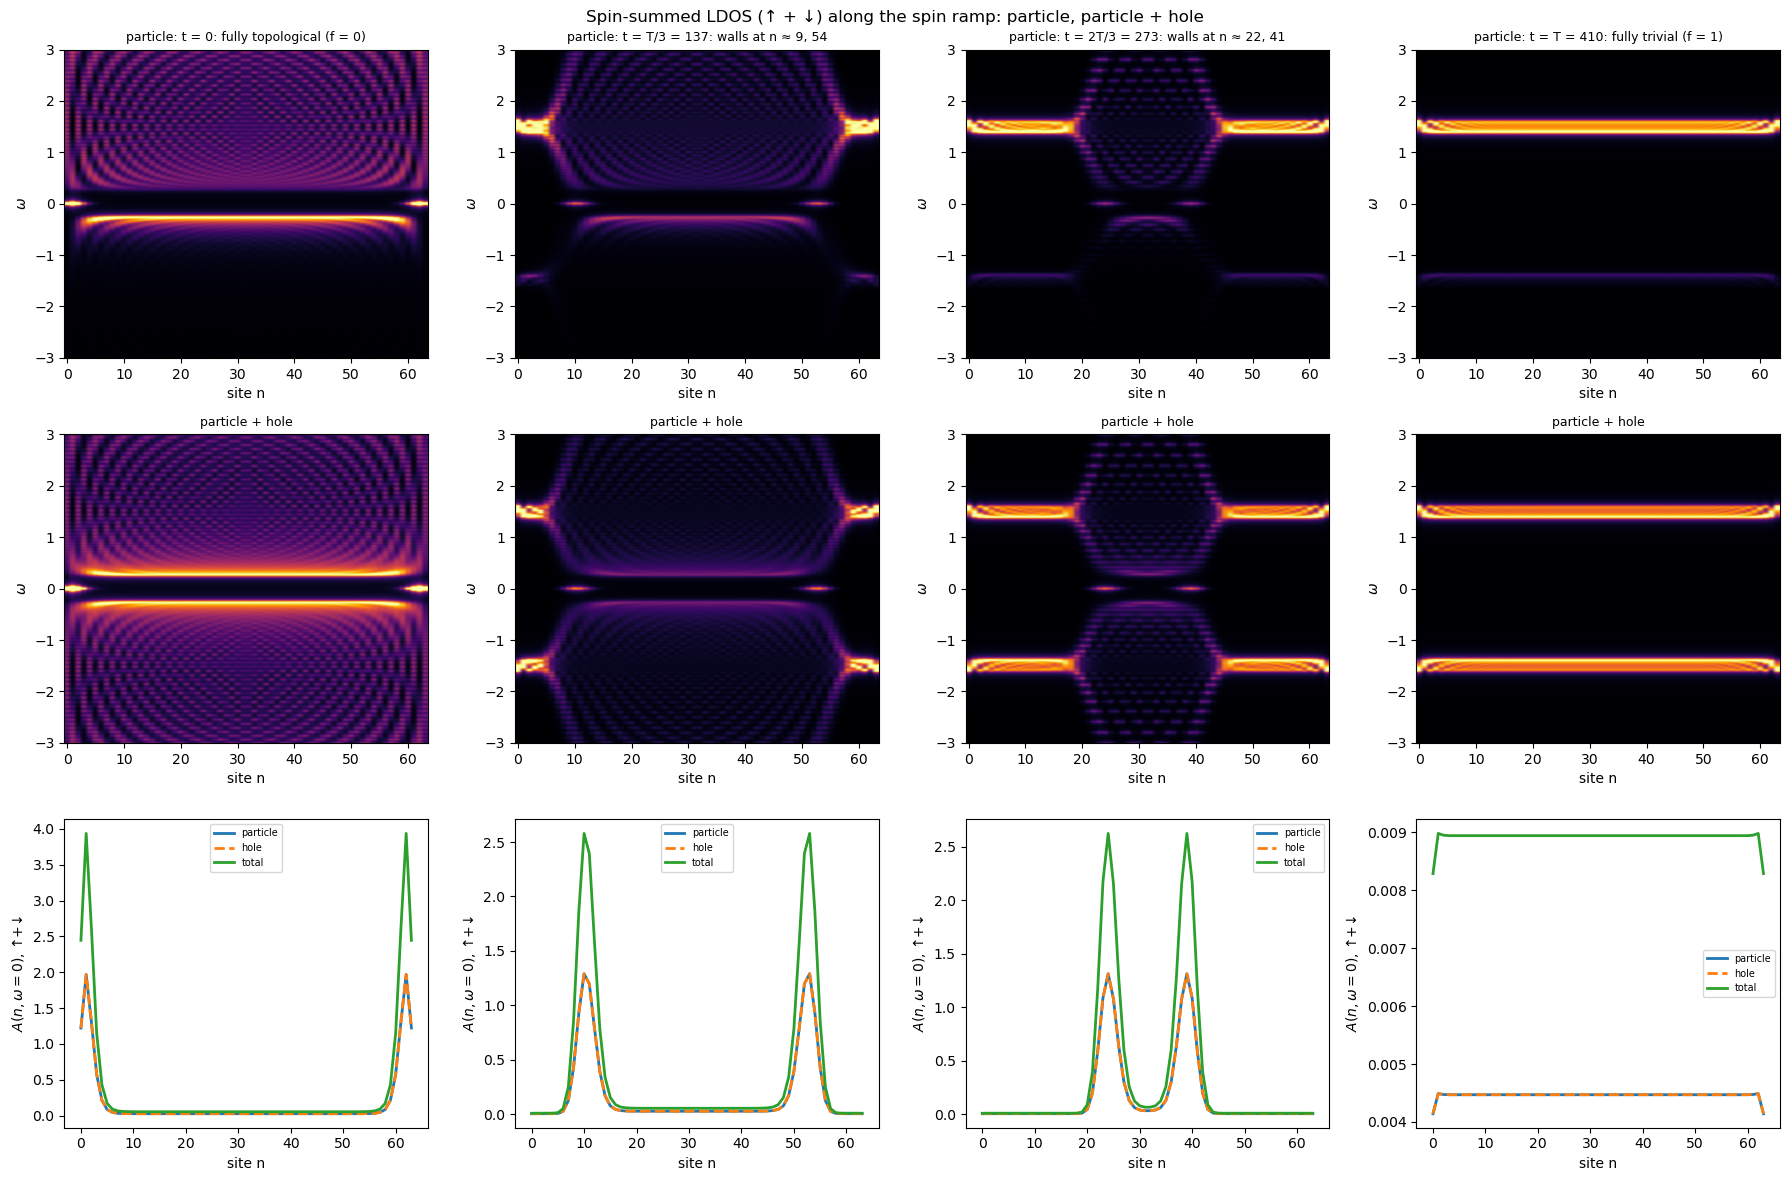

In [5]:
L = 6; N = 2**L
omega = np.linspace(-3, 3, 601)
eta = 0.03
i0 = np.argmin(np.abs(omega))
cmax = lambda A: np.sort(A.ravel())[int(np.ceil(0.995*A.size)) - 1]   # colour scale: 99.5th percentile

fig, ax = plt.subplots(3, 4, figsize=(18, 12))
results["ldos_omega"] = omega
for j, (name, f) in enumerate(cases_for(N)):
    en, wf = np.linalg.eigh(msh_ham(N, f))
    p, h = particle_hole_weights(wf)
    Ap, Ah = lorentz_ldos(en, p, omega, eta), lorentz_ldos(en, h, omega, eta)
    At = Ap + Ah
    results[f"ldos_p_{j}"], results[f"ldos_h_{j}"] = Ap, Ah
    print(f"{name:<40s} max|A_h(ω) − A_p(−ω)| = {np.max(np.abs(Ah - Ap[::-1])):.1e}")
    lrbt = [-0.5, N-0.5, omega[0], omega[-1]]
    for r, (A, ttl) in enumerate(((Ap, "particle: " + name), (At, "particle + hole"))):
        ax[r, j].imshow(A, extent=lrbt, aspect="auto", origin="lower", cmap="inferno", clim=(0, cmax(A)))
        ax[r, j].set_title(ttl, fontsize=9); ax[r, j].set_xlabel("site n"); ax[r, j].set_ylabel(r"$\omega$")
    ax[2, j].plot(np.arange(N), Ap[i0], lw=2, label="particle")
    ax[2, j].plot(np.arange(N), Ah[i0], "--", lw=2, label="hole")
    ax[2, j].plot(np.arange(N), At[i0], lw=2, label="total")
    ax[2, j].set_xlabel("site n"); ax[2, j].set_ylabel(r"$A(n, \omega=0)$, ↑+↓"); ax[2, j].legend(fontsize=7)
fig.suptitle("Spin-summed LDOS (↑ + ↓) along the spin ramp: particle, particle + hole")
fig.tight_layout()
plt.show()

## 4. Jackson-KPM LDOS

Port of the Julia `kpm_exact` and TensorBinding's `_kpm_weight_matrix` (Jackson kernel): the KPM LDOS from the
exact eigenpairs, i.e. what `get_ldos_spatial` converges to as the MPS truncation error goes to zero. The scale is
the `msh_tb` bound, $1.05\,(|\mu| + |J| + 2\sqrt{t^2+\alpha^2} + |\Delta|)$; results are in physical units (multiplied
by $\pi/\text{scale}$, as in the Julia cells).

Section 8a of the Julia notebook: the four spin-ramp snapshots (`cases_for`), `Ncheb = 1024`, 241 points, particle + hole
(sum rule 4 per site).

scale = 18.785261
t = 0: fully topological (f = 0)         max A = 2.594   ∫A dω per site: 4.0000 … 4.0000  (expected 4)
t = T/3 = 137: walls at n ≈ 9, 54        max A = 4.774   ∫A dω per site: 4.0000 … 4.0000  (expected 4)
t = 2T/3 = 273: walls at n ≈ 22, 41      max A = 4.854   ∫A dω per site: 4.0000 … 4.0000  (expected 4)
t = T = 410: fully trivial (f = 1)       max A = 4.854   ∫A dω per site: 4.0000 … 4.0000  (expected 4)


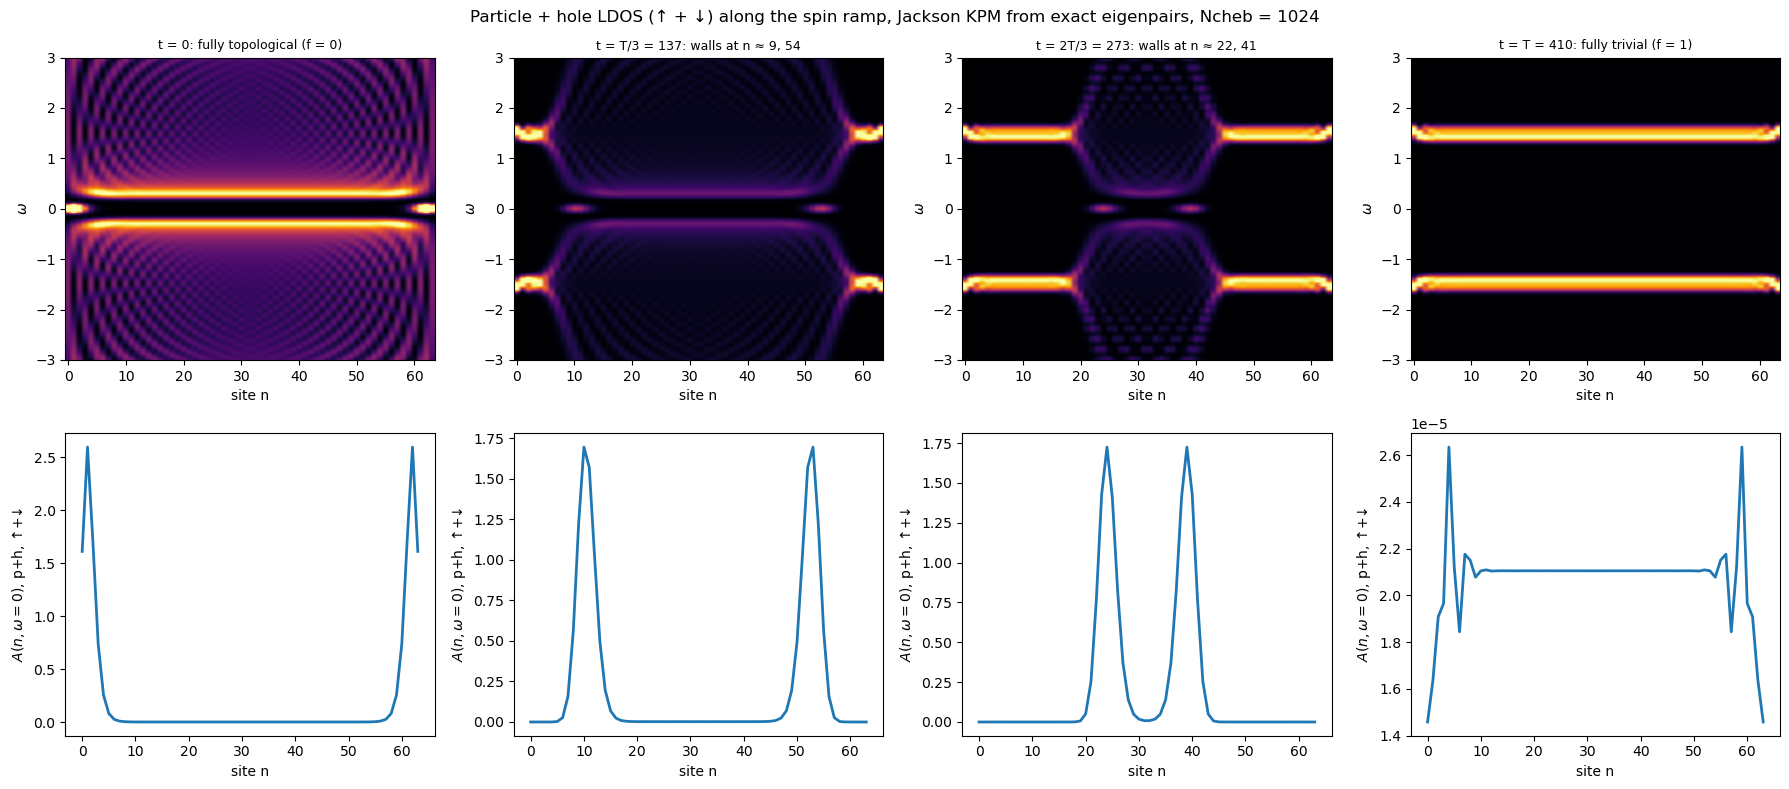

In [6]:
def kpm_scale(t=1.0, mu=-7.0, alpha=0.9, Delta=2.4, J=5.8):
    return 1.05 * (abs(mu) + abs(J) + 2*np.sqrt(t**2 + alpha**2) + abs(Delta))

def jackson(Ncheb):
    n = np.arange(Ncheb)   # unnormalized, N·g_n, as in TensorBinding's _kpm_kernel
    return (Ncheb - n) * np.cos(np.pi*n/Ncheb) + np.sin(np.pi*n/Ncheb) / np.tan(np.pi/Ncheb)

def kpm_weight_matrix(Ncheb, w):
    W = np.zeros((Ncheb, w.size))
    inside = np.abs(w) < 1
    c = np.where(np.arange(Ncheb) == 0, 1.0, 2.0) * jackson(Ncheb)
    W[:, inside] = c[:, None] * np.cos(np.arange(Ncheb)[:, None] * np.arccos(w[inside])[None, :])
    return W

def kpm_ldos(en, w, omega, Ncheb, scale, center=0.0):
    """Jackson-KPM LDOS (physical units), Nω x N, from eigenvalues and weights w[x, k]."""
    Et = (en - center) / scale
    wt = (omega - center) / scale
    T = np.cos(np.arange(Ncheb)[:, None] * np.arccos(np.clip(Et, -1, 1))[None, :])   # Ncheb x 4N
    mu_n = T @ w.T                                                                  # Ncheb x N
    A = (kpm_weight_matrix(Ncheb, wt).T @ mu_n) / (np.pi**2 * Ncheb * np.sqrt(np.maximum(1 - wt**2, 1e-300)))[:, None]
    A[np.abs(wt) >= 1] = 0
    return A * np.pi / scale

L = 6; N = 2**L
sc = kpm_scale(**params)

print(f"scale = {sc:.6f}")
omf = np.linspace(-0.999*sc, 0.999*sc, 20001)                # full spectrum for the sum rule

# section 8a: the four spin-ramp snapshots, Ncheb = 1024, particle + hole
om = np.linspace(-3, 3, 241)
results["kpm1024_omega"] = om
fig, ax = plt.subplots(2, 4, figsize=(18, 8))
i0 = np.argmin(np.abs(om))
for j, (name, f) in enumerate(cases_for(N)):
    en, wf = np.linalg.eigh(msh_ham(N, f))
    p, h = particle_hole_weights(wf)
    A = kpm_ldos(en, p + h, om, 1024, sc)
    results[f"kpm1024_ph_{j}"] = A
    I = kpm_ldos(en, p + h, omf, 1024, sc).sum(axis=0) * (omf[1] - omf[0])
    print(f"{name:<40s} max A = {A.max():.3f}   ∫A dω per site: {I.min():.4f} … {I.max():.4f}  (expected 4)")
    ax[0, j].imshow(A, extent=[-0.5, N-0.5, om[0], om[-1]], aspect="auto", origin="lower", cmap="inferno",
                    clim=(0, cmax(A)))
    ax[0, j].set_title(name, fontsize=9); ax[0, j].set_xlabel("site n"); ax[0, j].set_ylabel(r"$\omega$")
    ax[1, j].plot(np.arange(N), A[i0], lw=2)
    ax[1, j].set_xlabel("site n"); ax[1, j].set_ylabel(r"$A(n, \omega=0)$, p+h, ↑+↓")
fig.suptitle("Particle + hole LDOS (↑ + ↓) along the spin ramp, Jackson KPM from exact eigenpairs, Ncheb = 1024")
fig.tight_layout()
plt.show()

## 5. Majorana modes

The Majorana construction of `ferromagnetic_spin_chain_edit_ver2` (`takagi`, `individual_MZMs`, `fix_unitary`),
with the `np.repeat` position operator. `individual_MZMs` now also accepts `nzero`, which selects the `nzero`
states with the smallest $|E|$ (what the Julia code does) instead of the `|E| < tol` window; for short segments the
pair splitting is larger than any sensible `tol`.

The fermion $\psi_f = (\gamma_1 + i\gamma_2)/\sqrt{2}$ is taken as the $+E$ member, as in the Julia notebook, and
`fix_unitary` is followed by a swap so that column `2N` is always that $+E$ state.

In [7]:
# returns Hermitian conjugate
def dag(A, axis1=-2, axis2=-1):
    if A.ndim > 1:
        return A.swapaxes(axis1, axis2).conj()
    else:
        return A.conj()

# return tau_y sigma_y psi^* ("ltslts", "udd-u")
def PHconj(psi):
    N, n = psi.shape
    return (tysy @ psi.reshape(N // 4, 4, n).conj()).reshape(N, n)

# Takagi factorization
def takagi(A):
    # Diagonalize a complex symmetric matrix as A = U D U^T, U unitary and D diagonal
    B = dag(A)@A
    b, V = np.linalg.eigh(B)
    C = V.T@A@V
    X = C.real
    Y = C.imag
    w, W = np.linalg.eigh(X+Y)
    U = V@W
    z = np.sum(U*(A@U), axis=0)
    r = np.abs(z)
    U *= (r/z)**0.5
    return r, U.conj()

def individual_MZMs(E, M, Nx, Ny, tol=1e-3, nzero=None):
    """Separate the zero-energy subspace into localized Majoranas.

    nzero: if given, use the nzero states with the smallest |E| instead of |E| < tol.
    Returns mbs (4N x n, sorted by position), mask, M, and the Majorana centers ⟨x⟩.
    """
    if nzero is None:
        mask = np.abs(E) < tol
        if sum(mask) % 2 == 1:
            ind = np.ma.array(np.abs(E), mask=mask).argmin()
            mask[ind] = True
            warnings.warn(f"Adding E={E[ind]} to zero-energy subspace.")
    else:
        mask = np.zeros(E.size, bool)
        mask[np.argsort(np.abs(E))[:nzero]] = True

    psi = M[:, mask]

    # Majoranas (eigenstates of C)
    C = dag(psi) @ PHconj(psi)
    c, Z = takagi(C)
    gamma = psi @ Z

    # localize, site-major position operator
    x = np.repeat([i*Ny + j for i in range(Nx) for j in range(Ny)], 4)
    R = dag(gamma) * x @ gamma
    r, O = np.linalg.eigh(R.real)
    mbs = gamma @ O
    return mbs, mask, M, r

def fix_unitary(mbs, mask, M):
    """Pair the Majoranas 0-1, 2-3, ... into fermions and write them into M[:, mask]."""
    N, n = mbs.shape
    U = np.array([[1, 1], [1j, -1j]])/2**0.5
    phi = mbs @ np.kron(np.eye(n // 2), U)
    ind = np.arange(n).reshape(n//2, 2).swapaxes(0, 1).ravel()
    phi = phi[:, ind]
    ind = np.arange(n).reshape(2, n // 2)
    ind[0] = np.flip(ind[0])
    ind = ind.ravel()
    phi = phi[:, ind]
    M[:, mask] = phi
    return M

def majorana_fermion(H):
    """Majoranas γ1, γ2 and fermion ψf (+E member) of the lowest pair.

    Returns centers, γs (4N x 2), ψf, E_f and the fixed unitary M (column 2N = ψf, 2N-1 = Cψf).
    """
    N = H.shape[0] // 4
    en, wf = np.linalg.eigh(H)
    mbs, mask, M, centers = individual_MZMs(en, wf.copy(), N, 1, nzero=2)
    M = fix_unitary(mbs, mask, M)
    cols = np.flatnonzero(mask)
    E = np.real(np.einsum("ik,ij,jk->k", M[:, cols].conj(), H, M[:, cols]))
    if E[1] < 0:                                   # put the +E member in column 2N
        M[:, cols] = M[:, cols[::-1]]; E = E[::-1]
    return dict(centers=centers, gammas=mbs, psi_f=M[:, cols[1]], E_f=E[1], M=M, en=en)

def dQ_mode(psi):
    """ΔQ = ⟨ψ|τz|ψ⟩ = Σ |u|² − |v|²."""
    p, h = particle_hole_weights(psi[:, None])
    return np.sum(p) - np.sum(h)

def dn_mode(psi):
    """δn(x) = Σ_σ |u_σ(x)|² − |v_σ(x)|²."""
    p, h = particle_hole_weights(psi[:, None])
    return (p - h)[:, 0]

──  f = 0 (FM ẑ): Majoranas at the chain ends  ──
  Majorana centers ⟨x⟩ (0-indexed) = [ 1.41 61.59]
  ‖Cγᵢ − γᵢ‖ = [2.798e-14 7.200e-15],  max|⟨γᵢ|γⱼ⟩ − δᵢⱼ| = 4.4e-16,  max|Re H_ij| = 5.1e-17
  E_f = 1.179e-14 (exact 5.070e-15)
──  domain f = 0 for 16 ≤ n < 48: Majoranas at the walls  ──
  Majorana centers ⟨x⟩ (0-indexed) = [16.55 46.45]
  ‖Cγᵢ − γᵢ‖ = [8.360e-15 1.672e-14],  max|⟨γᵢ|γⱼ⟩ − δᵢⱼ| = 1.4e-15,  max|Re H_ij| = 4.1e-17
  E_f = 3.319e-08 (exact 3.319e-08)


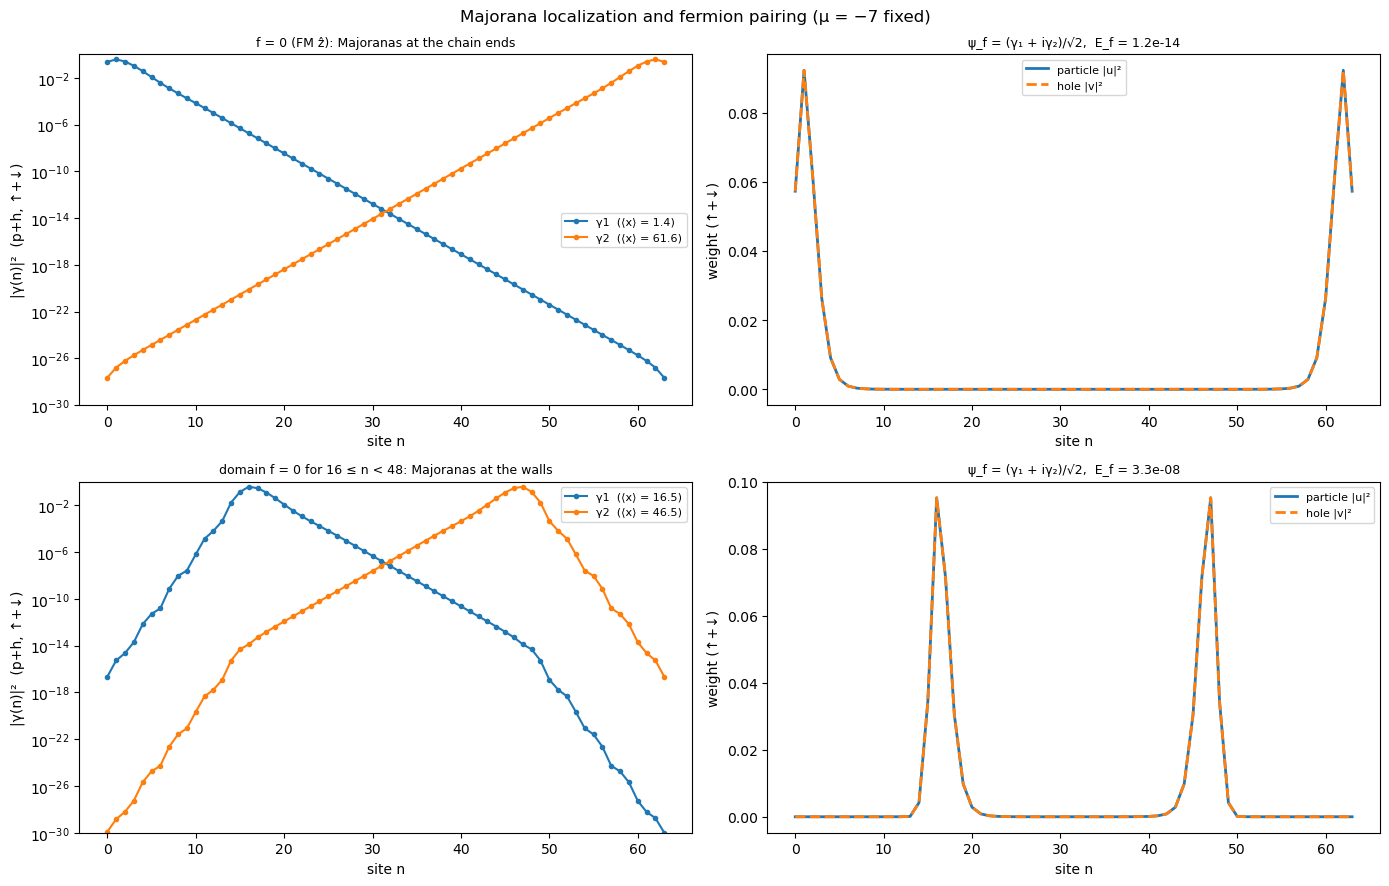

In [8]:
L = 6; N = 2**L
mz_cases = [("f = 0 (FM ẑ): Majoranas at the chain ends", lambda n: 0.0),
            (f"domain f = 0 for {N//4} ≤ n < {3*N//4}: Majoranas at the walls",
             lambda n: 0.0 if N//4 <= n < 3*N//4 else 1.0)]
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
for j, (name, f) in enumerate(mz_cases):
    print("── ", name, " ──")
    H = msh_ham(N, f)
    r = majorana_fermion(H)
    g = r["gammas"]
    E_sorted = np.sort(np.abs(r["en"]))
    print(f"  Majorana centers ⟨x⟩ (0-indexed) = {np.round(r['centers'], 2)}")
    print(f"  ‖Cγᵢ − γᵢ‖ = {np.round(np.linalg.norm(PHconj(g) - g, axis=0), 17)},  "
          f"max|⟨γᵢ|γⱼ⟩ − δᵢⱼ| = {np.max(np.abs(dag(g) @ g - np.eye(2))):.1e},  "
          f"max|Re H_ij| = {np.max(np.abs((dag(g) @ H @ g).real)):.1e}")
    print(f"  E_f = {r['E_f']:.3e} (exact {E_sorted[1]:.3e})")
    results[f"mzm_centers_{j}"], results[f"mzm_E_f_{j}"] = r["centers"], r["E_f"]
    results[f"mzm_gamma_weight_{j}"] = np.stack([sum(particle_hole_weights(g[:, [i]]))[:, 0] for i in range(2)])
    for i in range(2):
        ax[j, 0].semilogy(np.arange(N), np.maximum(results[f"mzm_gamma_weight_{j}"][i], 1e-30), "o-", ms=3,
                          label=f"γ{i+1}  (⟨x⟩ = {r['centers'][i]:.1f})")
    ax[j, 0].set_ylim(1e-30, 1); ax[j, 0].set_title(name, fontsize=9); ax[j, 0].legend(fontsize=8)
    ax[j, 0].set_xlabel("site n"); ax[j, 0].set_ylabel("|γ(n)|²  (p+h, ↑+↓)")
    u, v = particle_hole_weights(r["psi_f"][:, None])
    ax[j, 1].plot(np.arange(N), u, lw=2, label="particle |u|²")
    ax[j, 1].plot(np.arange(N), v, "--", lw=2, label="hole |v|²")
    ax[j, 1].set_title(f"ψ_f = (γ₁ + iγ₂)/√2,  E_f = {r['E_f']:.2g}", fontsize=9); ax[j, 1].legend(fontsize=8)
    ax[j, 1].set_xlabel("site n"); ax[j, 1].set_ylabel("weight (↑+↓)")
fig.suptitle("Majorana localization and fermion pairing (μ = −7 fixed)")
fig.tight_layout()
plt.show()

## 6. Charge difference vs Majorana separation

Topological (f = 0) segment of $\ell$ sites in the middle of the chain, f = 1 outside. Three values per $\ell$:

- $\Delta Q = \langle\psi_f|\tau_z|\psi_f\rangle$ (single-mode, what the Julia `majorana_pair_charge` computes),
- $Q(|1\rangle) - Q(|0\rangle)$ from the many-body charge density of the earlier notebook: $|0\rangle$ fills columns
  $0 \dots 2N-1$ of the fixed unitary, $|1\rangle$ replaces column $2N-1$ ($C\psi_f$) by column $2N$ ($\psi_f$),
- the Feynman–Hellmann value $-\partial E_f/\partial\mu$.

In [9]:
def segment(N, ell):
    return range((N - ell) // 2, (N - ell) // 2 + ell)

def f_segment(N, ell):
    seg = segment(N, ell)
    return lambda n: 0.0 if n in seg else 1.0

def charge_density(M, cols):
    """Spin-summed electron density per site of the Slater state filling columns `cols`."""
    N = M.shape[0] // 4
    G = M[:, cols] @ M[:, cols].T.conj()
    return np.diagonal(G).real.reshape(N, 4)[:, :2].sum(axis=1)

def pair_charge(L, ell, dmu=1e-4, **kw):
    N = 2**L
    H = msh_ham(N, f_segment(N, ell), **kw)
    r = majorana_fermion(H)
    M = r["M"]
    occ0 = np.arange(2*N)                               # |0⟩: columns 0 … 2N−1
    occ1 = np.r_[np.arange(2*N - 1), 2*N]              # |1⟩: 2N−1 → 2N
    drho = charge_density(M, occ1) - charge_density(M, occ0)
    mu = kw.get("mu", params["mu"])
    Eplus = lambda m: np.sort(np.abs(np.linalg.eigvalsh(msh_ham(N, f_segment(N, ell), **{**kw, "mu": m}))))[0]
    return dict(dQ=dQ_mode(r["psi_f"]), dQ_mb=drho.sum(), dQ_FH=-(Eplus(mu + dmu) - Eplus(mu - dmu)) / (2*dmu),
                E=r["E_f"], dn=dn_mode(r["psi_f"]), drho=drho)

L = 6; N = 2**L
ells = np.arange(2, 49, 2)
charge = [pair_charge(L, ell) for ell in ells]
for ell, c in zip(ells, charge):
    print(f"ℓ = {ell:2d}:  ΔQ = {c['dQ']:+.6e}  many-body {c['dQ_mb']:+.6e}  (−∂E/∂μ {c['dQ_FH']:+.3e})  "
          f"E_f = {c['E']:.3e}  max|δn − Δρ| = {np.max(np.abs(c['dn'] - c['drho'])):.1e}")
results["charge_ells"] = ells
results["charge_dQ"] = np.array([c["dQ"] for c in charge])
results["charge_dQ_mb"] = np.array([c["dQ_mb"] for c in charge])
results["charge_dQ_FH"] = np.array([c["dQ_FH"] for c in charge])
results["charge_E"] = np.array([c["E"] for c in charge])
results["charge_dn"] = np.array([c["dn"] for c in charge])

# fig, ax = plt.subplots(1, 2, figsize=(14, 5))
# ax[0].semilogy(ells, np.abs(results["charge_dQ"]), "o-", label=r"$|\langle\psi_f|\tau_z|\psi_f\rangle|$")
# ax[0].semilogy(ells, np.abs(results["charge_dQ_mb"]), "x--", label="many-body |Q(|1⟩) − Q(|0⟩)|")
# ax[0].semilogy(ells, np.abs(results["charge_dQ_FH"]), ":", lw=2, label="|∂E_f/∂μ|")
# ax[0].semilogy(ells, results["charge_E"], "-.", label="E_f")
# ax[0].set_xlabel("topological segment length ℓ"); ax[0].set_ylabel("|ΔQ|"); ax[0].legend(fontsize=8)
# ax[0].set_title("Charge difference vs Majorana separation")
# for ell, c in zip(ells, charge):
#     if ell in (8, 16, 24):
#         sc_ = np.max(np.abs(c["dn"]))
#         ax[1].plot(np.arange(N), c["dn"] / sc_, lw=1.5, label=f"ℓ = {ell}  (÷ {sc_:.2g})")
# ax[1].set_xlabel("site n"); ax[1].set_ylabel("δn(x) = n₁ − n₀ (↑+↓), normalized"); ax[1].legend(fontsize=8)
# fig.tight_layout()
# plt.show()

ℓ =  2:  ΔQ = +7.214509e-01  many-body +7.214509e-01  (−∂E/∂μ +7.215e-01)  E_f = 1.474e-01  max|δn − Δρ| = 1.7e-16
ℓ =  4:  ΔQ = +5.190618e-01  many-body +5.190618e-01  (−∂E/∂μ +5.191e-01)  E_f = 3.520e-02  max|δn − Δρ| = 5.8e-16
ℓ =  6:  ΔQ = +2.565048e-01  many-body +2.565048e-01  (−∂E/∂μ +2.565e-01)  E_f = 1.207e-02  max|δn − Δρ| = 1.0e-15
ℓ =  8:  ΔQ = +1.123403e-01  many-body +1.123403e-01  (−∂E/∂μ +1.123e-01)  E_f = 4.861e-03  max|δn − Δρ| = 5.0e-16
ℓ = 10:  ΔQ = +5.012842e-02  many-body +5.012842e-02  (−∂E/∂μ +5.013e-02)  E_f = 1.858e-03  max|δn − Δρ| = 6.9e-16
ℓ = 12:  ΔQ = +2.232592e-02  many-body +2.232592e-02  (−∂E/∂μ +2.233e-02)  E_f = 6.793e-04  max|δn − Δρ| = 8.6e-16
ℓ = 14:  ΔQ = +9.629467e-03  many-body +9.629467e-03  (−∂E/∂μ +9.629e-03)  E_f = 2.493e-04  max|δn − Δρ| = 2.1e-15
ℓ = 16:  ΔQ = +4.043733e-03  many-body +4.043733e-03  (−∂E/∂μ +4.044e-03)  E_f = 9.257e-05  max|δn − Δρ| = 4.4e-16
ℓ = 18:  ΔQ = +1.674243e-03  many-body +1.674243e-03  (−∂E/∂μ +1.674e-03)  E_f =

## 7. Spin ramp (CZ protocol)

Same ramp as the Julia `SpinRamp`: spins rotate from f = 0 to f = 1 starting at both chain ends and moving
inwards, $f_n(t) = \text{smoothstep}\big((t - t_0)/T_\text{rot} - \text{step}_T\,k_n\big)$ with $k_n = \min(n, N-1-n)$,
for the $(N - \ell_\text{final})/2$ outer sites on each side. (The earlier `spin_timedep` rotated from the right end only.)

Time evolution as in the earlier notebook, $\psi \leftarrow V e^{-iE\,dt} V^\dagger \psi$ from the instantaneous
eigenpairs, but with $H$ taken at the midpoint $t + dt/2$ of each step (the Julia `run_spin_ramp_exact` and
TDVP code do the same). Only the pair $C\psi_f$, $\psi_f$ is evolved: the charge-density difference of $|1\rangle$
and $|0\rangle$ only involves these two columns. At $t = T$ the state is projected on the instantaneous $\pm E$ pair:
leakage $= 1 - p_+ - p_-$.

The ramp is run twice: with this notebook's Rashba sign ($\alpha = 0.9$) and with the Julia notebook's
($\alpha = -0.9$ here). Only the second is expected to match the Julia numbers (exact: leak = 2.143e-04,
ΔQ(T) = +0.516615); the difference between the two shows how much the sign convention matters for the dynamics.
Samples are taken at the same steps as the Julia `run_spin_ramp_exact`.

α = +0.9 (paper): E(0) = 1.2e-14, leak = 2.179e-04, wrong branch = 9.2e-28, ΔQ(T) = +0.523281 (adiabatic +0.519062)
α = -0.9 (julia): E(0) = 1.2e-14, leak = 2.143e-04, wrong branch = 1.2e-26, ΔQ(T) = +0.516615 (adiabatic +0.519062)
max_t |ΔQ_paper(t) − ΔQ_julia(t)| = 2.4e-02


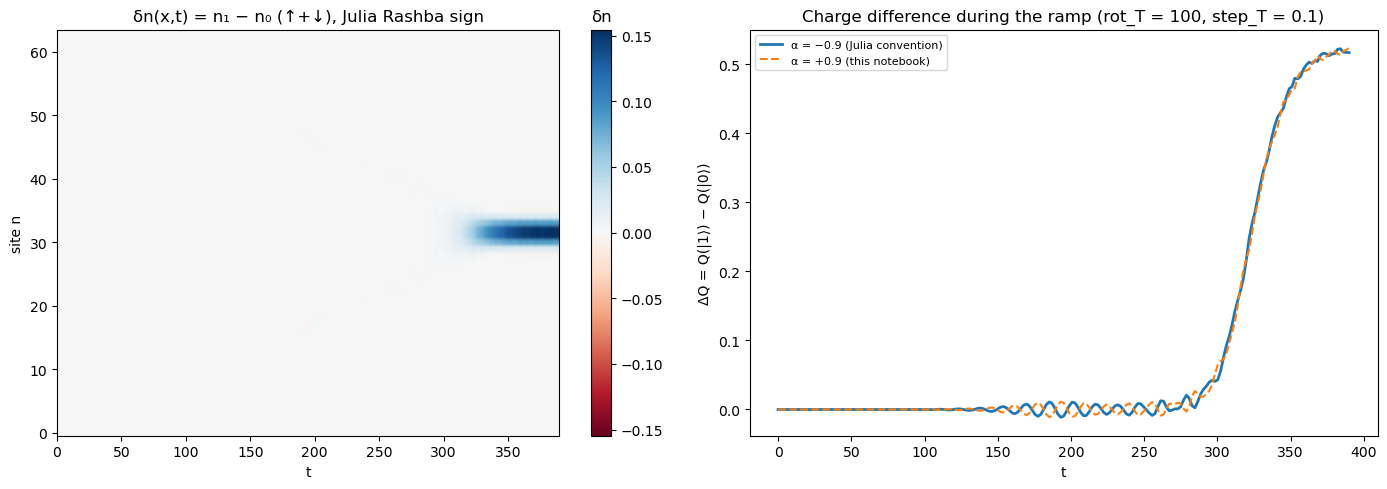

In [10]:
# ramp_f and ramp_duration are defined in the model cell (section 0)

def run_spin_ramp(L, dt=0.1, nsnap=200, model_kw={}, **paramsT):
    N = 2**L
    ham = lambda f: msh_ham(N, f, **model_kw)
    T = ramp_duration(N, **paramsT)
    nsteps = int(round(T / dt)); dt = T / nsteps
    r0 = majorana_fermion(ham(ramp_f(0.0, N, **paramsT)))
    psi = np.stack([PHconj(r0["psi_f"][:, None])[:, 0], r0["psi_f"]], axis=1)   # (Cψf, ψf)
    snap = set(np.round(np.linspace(1, nsteps + 1, nsnap + 1)).astype(int) - 1)   # same samples as Julia
    ts, dQ_t, dn_t = [], [], []
    for l in range(nsteps + 1):
        if l in snap:
            ts.append(l * dt); dQ_t.append(dQ_mode(psi[:, 1])); dn_t.append(dn_mode(psi[:, 1]))
        if l == nsteps:
            break
        en_pert, psi_pert = np.linalg.eigh(ham(ramp_f((l + 0.5) * dt, N, **paramsT)))
        S = psi_pert * np.exp(-1j * en_pert * dt) @ psi_pert.T.conj()
        psi = S @ psi
        psi = psi / np.linalg.norm(psi, axis=0)
    # end of ramp: overlap with the instantaneous ±E pair
    en, wf = np.linalg.eigh(ham(ramp_f(T, N, **paramsT)))
    ip = np.flatnonzero(en > 0)[0]
    pp, pm = np.abs(wf[:, ip].conj() @ psi[:, 1])**2, np.abs(wf[:, ip - 1].conj() @ psi[:, 1])**2
    sgn = -1 if pm > pp else 1
    if sgn == -1:
        pp, pm = pm, pp
    return dict(T=T, dt=dt, E0=r0["E_f"], leak=1 - pp - pm, p_wrong=pm,
                dQ_final=sgn * dQ_mode(psi[:, 1]), dQ_adiabatic=dQ_mode(wf[:, ip]),
                times=np.array(ts), dQ_t=sgn * np.array(dQ_t), dn_t=sgn * np.array(dn_t).T)

ramp_params = dict(ell_final=4, rot_T=100.0, step_T=0.1)
ramps = {}
for tag, alpha in (("paper", params["alpha"]), ("julia", -params["alpha"])):
    r = run_spin_ramp(6, model_kw=dict(alpha=alpha), **ramp_params)
    ramps[tag] = r
    print(f"α = {alpha:+.1f} ({tag:5s}): E(0) = {r['E0']:.1e}, leak = {r['leak']:.3e}, wrong branch = {r['p_wrong']:.1e}, "
          f"ΔQ(T) = {r['dQ_final']:+.6f} (adiabatic {r['dQ_adiabatic']:+.6f})")
    for key in ("times", "dQ_t", "dn_t", "leak", "p_wrong", "dQ_final", "dQ_adiabatic"):
        results[f"ramp_{tag}_{key}"] = r[key]
print(f"max_t |ΔQ_paper(t) − ΔQ_julia(t)| = {np.max(np.abs(ramps['paper']['dQ_t'] - ramps['julia']['dQ_t'])):.1e}")
ramp = ramps["julia"]

N = 64
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
lim = np.max(np.abs(ramp["dn_t"]))
im = ax[0].imshow(ramp["dn_t"], extent=[ramp["times"][0], ramp["times"][-1], -0.5, N-0.5], aspect="auto",
                  origin="lower", cmap="RdBu", clim=(-lim, lim))
fig.colorbar(im, ax=ax[0]).ax.set_title("δn")
ax[0].set_xlabel("t"); ax[0].set_ylabel("site n")
ax[0].set_title("δn(x,t) = n₁ − n₀ (↑+↓), Julia Rashba sign")
ax[1].plot(ramps["julia"]["times"], ramps["julia"]["dQ_t"], lw=2, label="α = −0.9 (Julia convention)")
ax[1].plot(ramps["paper"]["times"], ramps["paper"]["dQ_t"], "--", lw=1.5, label="α = +0.9 (this notebook)")
ax[1].legend(fontsize=8)
ax[1].set_xlabel("t"); ax[1].set_ylabel("ΔQ = Q(|1⟩) − Q(|0⟩)")
ax[1].set_title(f"Charge difference during the ramp (rot_T = {ramp_params['rot_T']:g}, step_T = {ramp_params['step_T']:g})")
fig.tight_layout()
plt.show()

### 7b. Interactive views of the ramp

`plot_spins` and `plot_zero_energy_ldos` from `ferromagnetic_spin_chain_edit_ver2`, adapted to this notebook: the
spins follow the two-sided ramp of section 7 (`ramp_f`, `ramp_params`) and $H$ is `msh_ham` (singlet pairing).
The slider `l` picks the time `ts[l]`. The LDOS is the spin-summed particle part ($\uparrow + \downarrow$), $\eta = 10^{-2}$.

In [11]:
from ipywidgets import interact

N = 64
ts = np.linspace(0, ramp_duration(N, **ramp_params), 201)

In [ ]:
@interact(l=(0, ts.size-1, 1))
def plot_spins(l=0):
    f = ramp_f(ts[l], N, **ramp_params)
    S = spin_texture(f, N)

    pos = np.array(list(S.keys()))
    spins = np.array(list(S.values()))

    x = pos.T
    y = np.zeros(x.size)
    sx, sy, sz = spins.T
    c = (1+spins)/2
    coords = np.array([(i,0) for i in range(N)])

    fig, axs = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
    ax = axs[0]
    ax.scatter(coords[:,0], coords[:,1], color="white", s=1)
    ax.quiver(x, y, sx, sy, color=c, angles='xy', scale_units='xy', scale=3, width=0.005, pivot='mid')
    ax.set_facecolor('k')
    ax.set_xlim(-0.5, N-0.5)

    en, wf = np.linalg.eigh(msh_ham(N, f))
    print(f"t = {ts[l]:.1f}:", en[2*N-6:2*N+6])

    omegas = np.linspace(-2.0, 2.0, 201)
    p, h = particle_hole_weights(wf)
    ldos_p = lorentz_ldos(en, p, omegas, 1e-2)   # Nω x N
    ldos_ph = ldos_p + lorentz_ldos(en, h, omegas, 1e-2)
    lrbt = [-0.5, N-0.5, omegas[0], omegas[-1]]
    for a, A, title in ((axs[0], ldos_p, "particle"), (axs[1], ldos_ph, "particle + hole")):
        im = a.imshow(A, extent=lrbt, aspect="auto", origin="lower")
        fig.colorbar(im, ax=a)
        a.set_title(title)
        a.set_ylabel(r'$\omega$')
    axs[1].set_xlabel(r'$x\left[a\right]$')

    plt.show()

In [ ]:
@interact(l=(0, ts.size-1, 1))
def plot_zero_energy_ldos(l=0):
    en, wf = np.linalg.eigh(msh_ham(N, ramp_f(ts[l], N, **ramp_params)))

    p, h = particle_hole_weights(wf)
    ldos_p = lorentz_ldos(en, p, np.array([0.0]), 1e-2)[0]
    ldos_h = lorentz_ldos(en, h, np.array([0.0]), 1e-2)[0]

    fig, ax = plt.subplots()
    ax.plot(np.arange(N), ldos_p, label="particle")
    ax.plot(np.arange(N), ldos_p + ldos_h, label="particle + hole")
    ax.legend()

    ax.set_ylabel(r'$N(x, \omega = 0)$')
    ax.set_xlabel(r'$x\left[a\right]$')
    ax.set_title(f"t = {ts[l]:.1f}")

    plt.show()

## Save results

In [14]:
np.savez("msh_compare_python.npz", **{k: np.asarray(v) for k, v in results.items()})
print(f"saved {len(results)} arrays to msh_compare_python.npz")

saved 42 arrays to msh_compare_python.npz
